# MINI PROJECT - CPUT

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

c:\Users\user\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


# Load the datatest

In [3]:
iris = load_iris()
X, y = iris.data, iris.target
df = pd.DataFrame(X, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(y, iris.target_names)

# EDA

In [4]:
print(df.describe())

       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


# class distribution

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


<Axes: xlabel='species', ylabel='count'>

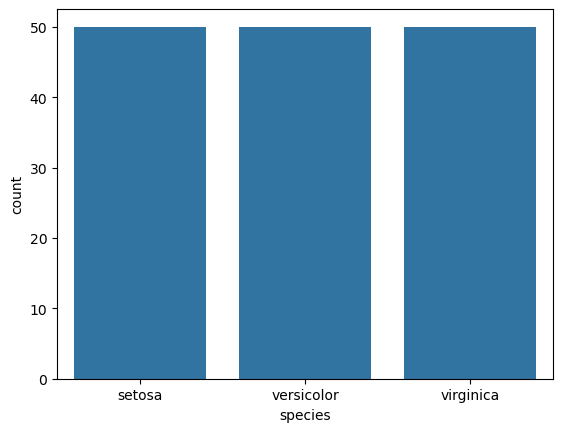

In [6]:
print(df['species'].value_counts())
sns.countplot(x='species', data=df)

coerrelation heatmap

<Axes: >

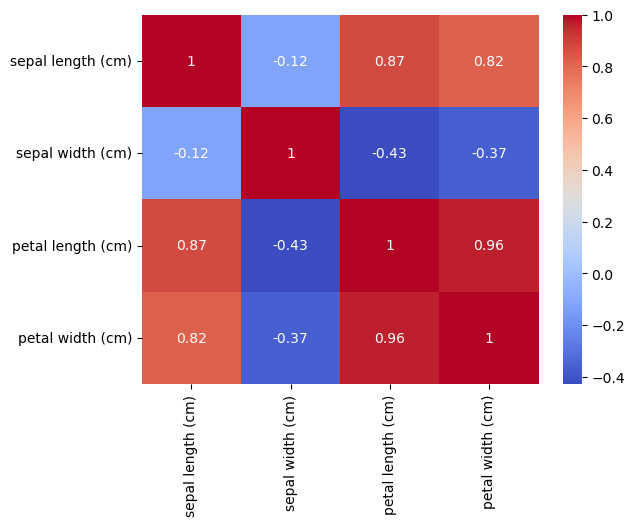

In [8]:
sns.heatmap(df.iloc[:, : 4].corr(), annot=True, cmap='coolwarm')

# Train - Test -Split 

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state= 42, stratify = y
)

# Feature scaling

In [10]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train then Model 

In [12]:
model = RandomForestClassifier(n_estimators = 100, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

# Make Predictions

In [13]:
y_pred = model.predict(X_test)

# Evaluate the model

In [14]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.2%}")
print("Classification Report:", (classification_report(y_test, y_pred, target_names=iris.target_names)))

Accuracy: 90.00%
Classification Report:               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30

